# FD001 remaining useful life: nine models compared

This notebook builds models that predict **remaining useful life (RUL, in operating cycles)**, scores them **training engines first**, and ends with one table of R2, RMSE and MAE for every model.

| Model | Input |
| --- | --- |
| Mean baseline, Linear Regression, Logistic Regression (on bands), Bayesian Ridge, SVM (SVR), Decision Tree, Random Forest, XGBoost | The 12 sensors kept by the EDA, plus causal rolling mean and standard deviation over the latest 5 and 10 rows (60 columns) |
| LSTM | The last 30 cycles of the same 12 sensors, scaled (a sequence) |

The target is `rul_cycles`, uncapped (FR06). The mean baseline (FR07) is a reference: it always predicts the average life, and every real model has to beat it.

**Order of evaluation**
1. Score every model on the **training engines**, using every row.
2. Then score on the **validation engines** the models never trained on. This section is there because **training scores show how well a model memorised its lessons, not how well it predicts**. Expect them to look better than anything else in this notebook.

**The split is 70:30 by whole engine.** Of the 100 training-file engines, 70 are used for training and 30 are held back for validation (seed 42, `VAL_FRACTION = 0.30` at the top of the notebook). This is a train/validation split inside the NASA training file. The official test set is separate and stays closed.

**What this notebook does not touch.** The official test labels (`RUL_FD001.csv`) stay closed until model selection is frozen (FR03). The test and RUL files are loaded only to confirm they are present, then discarded.

**Inputs** (relative to the project root): `data/csv_preview/*.csv` and `artifacts/eda/eda_split_and_columns.json` (the sensors the EDA kept). The 70:30 engine split is made in this notebook with the same method as the project's `src/splits.py`, and it is saved to `artifacts/model/`. The project's own pipeline split in `data/processed/` is not changed.

**Requirements.** `pip install scikit-learn torch xgboost` first, as none is in `requirements.txt` yet. Requirement IDs (FR02 and so on) refer to the functional requirements document.

In [3]:
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from sklearn.dummy import DummyRegressor
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.linear_model import BayesianRidge, LinearRegression, LogisticRegression
    from sklearn.metrics import r2_score
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVR
    from sklearn.tree import DecisionTreeRegressor
except ImportError as exc:
    raise ImportError("scikit-learn is missing. Install it with: pip install scikit-learn") from exc
try:
    import torch
    from torch import nn
except ImportError as exc:
    raise ImportError("PyTorch is missing. Install it with: pip install torch") from exc
try:
    from xgboost import XGBRegressor
except Exception as exc:
    raise ImportError(
        "XGBoost could not be loaded. Install it with: pip install xgboost "
        "(on a Mac, if the error mentions libomp, also run: brew install libomp)"
    ) from exc

# ---- configuration ------------------------------------------------------------
SEED = 42
VAL_FRACTION = 0.30             # 70:30 split by whole engine (FR03)
ROLL_WINDOWS = (5, 10)          # FR05: latest 5 and 10 observed rows
SEQ_LEN = 30                    # LSTM looks at the last 30 cycles
LSTM_HIDDEN = 64
LSTM_LAYERS = 2
LSTM_DROPOUT = 0.1
LSTM_EPOCHS = 30
LSTM_BATCH = 256
LSTM_LR = 1e-3
RUL_SCALE = 100.0               # LSTM target = RUL / 100 (scaled back after prediction)
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
OVER_TOL = 20                   # FR09: count predictions that overestimate by more than 20 cycles
MIN_CUTOFF = 31                 # shortest history among the official test engines
MIN_ENDPOINT_RUL = 7            # smallest remaining life among the official test engines
SAVE_OUTPUTS = True

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cpu")    # CPU keeps results reproducible

# ---- plot style: grey for the baseline, blue for the Random Forest, orange for the LSTM ----
INK, GRID = "#1F2933", "#E4E7EB"
COLORS = {"Mean baseline": "#8B939C", "Random Forest": "#2F6FB5", "LSTM": "#C4660F"}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#B8BEC6", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def find_project_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "csv_preview" / "train_FD001.csv").exists():
            return p
    raise FileNotFoundError(
        "Could not find data/csv_preview/train_FD001.csv in this folder or any parent. "
        "Open the notebook from inside the project folder."
    )


ROOT = find_project_root()
print("Project root:", ROOT)
print("torch", torch.__version__, "| device:", DEVICE)

Project root: /Users/joseph/Desktop/RUL_prediction/TurbofanHPC_RUL_prediction
torch 2.8.0 | device: cpu


## 1. Load the data and make the 70:30 split

Engines are split **as whole engines, never by row** (FR03), because neighbouring rows of one engine look almost identical and a row split would leak. The split uses the same method as the project's `src/splits.py`. The 12 sensors come from the EDA's saved column decisions, and a check in section 2 confirms the same choice comes out when only the training engines are used (FR04). `engine_id` and `cycle` are never model inputs.

In [4]:
CSV_DIR = ROOT / "data" / "csv_preview"
train_all = pd.read_csv(CSV_DIR / "train_FD001.csv")
test_raw = pd.read_csv(CSV_DIR / "test_FD001.csv")
rul_raw = pd.read_csv(CSV_DIR / "RUL_FD001.csv")

print(f"train {train_all.shape} | test {test_raw.shape} | RUL file {rul_raw.shape}")
assert list(train_all.columns) == list(test_raw.columns), "train and test columns differ"
assert len(rul_raw) == test_raw["engine_id"].nunique(), "RUL file must have one value per test engine"

# The official test set stays closed (FR03). We only needed to confirm the files are there.
del test_raw, rul_raw
print("Official test data and labels loaded for a shape check only, then discarded.")

eda = json.loads((ROOT / "artifacts" / "eda" / "eda_split_and_columns.json").read_text())


def split_engines(engine_ids, val_fraction, seed):
    # Same method as src/splits.py (FR03): a seeded random draw of whole engines for validation
    ids = np.array(sorted({int(e) for e in engine_ids}))
    rng = np.random.default_rng(seed)
    n_val = max(1, int(round(len(ids) * val_fraction)))
    val = np.sort(rng.choice(ids, size=n_val, replace=False))
    train = np.setdiff1d(ids, val)
    return [int(x) for x in train], [int(x) for x in val]


dev_ids, val_ids = split_engines(train_all["engine_id"].unique(), VAL_FRACTION, SEED)
assert set(dev_ids).isdisjoint(val_ids), "training and validation engines overlap"
assert set(dev_ids) | set(val_ids) == set(train_all["engine_id"].unique()), "split does not cover all engines"
print(f"Split (seed {SEED}): {len(dev_ids)} training engines, {len(val_ids)} validation engines "
      f"= {100 * len(dev_ids) / (len(dev_ids) + len(val_ids)):.0f}:{100 * len(val_ids) / (len(dev_ids) + len(val_ids)):.0f}")
print("Validation engine ids:", val_ids)

# labels used in every results table
TRAIN_LABEL = f"Train: {len(dev_ids)} engines, all rows"
VAL_LABEL = f"Validation: {len(val_ids)} engines, all rows"
END_LABEL = "Validation: 1 endpoint per engine"

# save the split so later steps (MLflow, tuning) can reuse exactly these engines
if SAVE_OUTPUTS:
    split_dir = ROOT / "artifacts" / "model"
    split_dir.mkdir(parents=True, exist_ok=True)
    manifest = {"seed": SEED, "val_fraction": VAL_FRACTION, "n_train_engines": len(dev_ids),
                "n_val_engines": len(val_ids), "train_engine_ids": dev_ids, "val_engine_ids": val_ids}
    (split_dir / f"split_manifest_{len(dev_ids)}_{len(val_ids)}.json").write_text(json.dumps(manifest, indent=2))

pipeline_manifest = ROOT / "data" / "processed" / "split_manifest.json"
if pipeline_manifest.exists():
    pm = json.loads(pipeline_manifest.read_text())
    print(f"For reference, the project pipeline's own split is {pm['n_train_engines']}:{pm['n_val_engines']}. "
          "This notebook uses its own split and does not change that file.")

SENSORS = [c for c in eda["keep"] if c.startswith("sensor")]
assert len(SENSORS) > 0 and all(c in train_all.columns for c in SENSORS)
print(f"{len(SENSORS)} sensors kept by the EDA:", SENSORS)

train (20631, 26) | test (13096, 26) | RUL file (100, 2)
Official test data and labels loaded for a shape check only, then discarded.
Split (seed 42): 70 training engines, 30 validation engines = 70:30
Validation engine ids: [7, 8, 12, 16, 17, 33, 35, 40, 41, 43, 45, 46, 48, 54, 55, 56, 61, 62, 64, 66, 68, 75, 77, 81, 88, 89, 95, 96, 98, 100]
For reference, the project pipeline's own split is 80:20. This notebook uses its own split and does not change that file.
12 sensors kept by the EDA: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 2. Target and features

**Target (FR02, FR06).** RUL at a row is the engine's final recorded cycle minus the current cycle, uncapped.

**Random Forest features (FR05).** The raw reading plus the rolling mean and standard deviation over the latest 5 and 10 rows of the *same engine*. Windows look backwards only, need at least one observation, and use `ddof=0`. The check below proves that cutting off the future leaves earlier feature values unchanged (AT03).

In [5]:
# ---- target (FR02, FR06) -----------------------------------------------------------
train_all = train_all.sort_values(["engine_id", "cycle"]).reset_index(drop=True)
train_all["rul_cycles"] = train_all.groupby("engine_id")["cycle"].transform("max") - train_all["cycle"]
assert train_all.groupby("engine_id")["rul_cycles"].min().eq(0).all(), "every engine must end at RUL 0"


# ---- causal rolling features (FR05) -------------------------------------------------
def feature_names():
    names = list(SENSORS)
    for w in ROLL_WINDOWS:
        for s in SENSORS:
            names += [f"{s}_mean_{w}", f"{s}_std_{w}"]
    return names


def add_rolling_features(df):
    df = df.sort_values(["engine_id", "cycle"]).reset_index(drop=True)
    grouped = df.groupby("engine_id")[SENSORS]
    new_cols = {}
    for w in ROLL_WINDOWS:
        roll = grouped.rolling(window=w, min_periods=1)
        mean = roll.mean().reset_index(level=0, drop=True).sort_index()
        std = roll.std(ddof=0).reset_index(level=0, drop=True).sort_index()
        for s in SENSORS:
            new_cols[f"{s}_mean_{w}"] = mean[s]
            new_cols[f"{s}_std_{w}"] = std[s]
    return pd.concat([df, pd.DataFrame(new_cols)], axis=1)


FEATURES = feature_names()
feats = add_rolling_features(train_all)

# ---- leakage check (AT03): chopping off the future must not change earlier features ----
one = train_all[train_all["engine_id"] == dev_ids[0]]
full = add_rolling_features(one)
cut = add_rolling_features(one.iloc[:60])
assert np.allclose(full.iloc[:60][FEATURES].to_numpy(), cut[FEATURES].to_numpy()), "features use future rows"
print("Leakage check passed: features at cycle 60 are identical with or without later cycles.")

dev_df = feats[feats["engine_id"].isin(dev_ids)].reset_index(drop=True)
val_df = feats[feats["engine_id"].isin(val_ids)].reset_index(drop=True)
print(f"{len(FEATURES)} Random Forest features | training rows {len(dev_df):,} | validation rows {len(val_df):,}")
display(dev_df[["engine_id", "cycle", "rul_cycles"] + FEATURES[:3] + [f"{SENSORS[0]}_mean_5", f"{SENSORS[0]}_std_5"]].head())


# ---- re-check the EDA's sensor choice using the TRAINING engines only (FR04) -------------------------------
def recheck_sensor_choice(frame, thresholds):
    import warnings
    cols = [f"sensor_{i}" for i in range(1, 22)]
    per_engine = {}
    for eid, g in frame.groupby("engine_id"):
        with warnings.catch_warnings(), np.errstate(all="ignore"):
            warnings.simplefilter("ignore")
            per_engine[eid] = g[cols].rank().corrwith(g["cycle"])   # trend with age inside one engine
    rho = pd.DataFrame(per_engine).T
    median_rho = rho.median()
    consistency = np.sign(rho).eq(np.sign(median_rho)).mean()      # share of engines trending the same way
    varying = frame[cols].std() > 1e-12
    many_values = frame[cols].nunique() > 5
    return [c for c in cols if varying[c] and many_values[c]
            and abs(median_rho[c]) >= thresholds["trend_min_rho"]
            and consistency[c] >= thresholds["trend_min_consistency"]]


rechecked = recheck_sensor_choice(dev_df, eda["thresholds"])
if sorted(rechecked) == sorted(SENSORS):
    print(f"Sensor choice re-checked on the {len(dev_ids)} training engines only: the same {len(SENSORS)} sensors. "
          "The EDA's list is safe to use.")
else:
    print("WARNING: the sensor choice differs when only the training engines are used.")
    print("  only in the EDA list:", sorted(set(SENSORS) - set(rechecked)))
    print("  only in the re-check:", sorted(set(rechecked) - set(SENSORS)))

Leakage check passed: features at cycle 60 are identical with or without later cycles.
60 Random Forest features | training rows 14,128 | validation rows 6,503


,engine_id,cycle,rul_cycles,sensor_2,sensor_3,sensor_4,sensor_2_mean_5,sensor_2_std_5
0,1,1,191,641.82,"1,589.70","1,400.60",641.82,0.00
1,1,2,190,642.15,"1,591.82","1,403.14",641.99,0.16
2,1,3,189,642.35,"1,587.99","1,404.20",642.11,0.22
3,1,4,188,642.35,"1,582.79","1,401.87",642.17,0.22
4,1,5,187,642.37,"1,582.85","1,406.22",642.21,0.21


Sensor choice re-checked on the 70 training engines only: the same 12 sensors. The EDA's list is safe to use.


## 3. How we score

Every table uses the same measures (FR09, FR10). **Error is predicted minus actual**, so a positive error means the model overestimates the life left.

| Measure | Meaning |
| --- | --- |
| MAE | Average size of the error, in cycles |
| RMSE | Like MAE but penalises big misses more |
| R2 (R squared) | The share of the variation in remaining life that the model explains. 1 is perfect, 0 means no better than always predicting the average, and below 0 means worse than that. It is calculated over all the rows being scored together |
| mean signed error | Average error with its sign. Above 0 means the model leans optimistic |
| over by more than 20 (%) | Share of predictions that overestimate by more than 20 cycles, the risky direction |
| engine-avg MAE / RMSE | The error averaged per engine, so long-lived engines (more rows) do not dominate |

In [6]:
def regression_report(rows, pred, name):
    y = rows["rul_cycles"].to_numpy(float)
    err = np.asarray(pred, float) - y
    per_engine = (
        pd.DataFrame({"engine_id": rows["engine_id"].to_numpy(), "abs": np.abs(err), "sq": err ** 2})
        .groupby("engine_id").agg(mae=("abs", "mean"), mse=("sq", "mean"))
    )
    return {
        "model": name,
        "rows": len(y),
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "R2": r2_score(y, pred),
        "mean signed error": err.mean(),
        f"over by >{OVER_TOL} (%)": 100 * np.mean(err > OVER_TOL),
        "engine-avg MAE": per_engine["mae"].mean(),
        "engine-avg RMSE": np.sqrt(per_engine["mse"]).mean(),
    }


def clip_nonneg(p):
    return np.clip(np.asarray(p, float), 0, None)   # FR06: predictions are never negative

## 4. Mean baseline and Random Forest

The baseline always predicts the average RUL seen in training. Any real model has to beat it. The Random Forest uses sensible first-pass settings and has **not been tuned**; tuning belongs on validation engines later (FR08).

In [7]:
X_dev, y_dev = dev_df[FEATURES], dev_df["rul_cycles"]

baseline = DummyRegressor(strategy="mean").fit(X_dev, y_dev)
print(f"Mean baseline always predicts {baseline.constant_[0, 0]:.1f} cycles")

t0 = time.time()
rf = RandomForestRegressor(**RF_PARAMS).fit(X_dev, y_dev)
print(f"Random Forest trained on {len(X_dev):,} rows in {time.time() - t0:.0f} s")

Mean baseline always predicts 105.7 cycles
Random Forest trained on 14,128 rows in 22 s


## 5. LSTM

An LSTM reads a **sequence** and keeps a running memory of it, so it can learn its own summaries of how the sensors have moved, instead of relying on hand-built rolling averages.

- **Input.** For each row, the last 30 cycles of the 12 sensors, standardised with a scaler fitted on the training engines only (FR04). For the first 29 cycles of an engine the window is padded by repeating its first reading.
- **Causal.** A window only ever contains the current and earlier cycles, never later ones.
- **Network.** Two LSTM layers of 64 units, then a small layer that outputs one number: RUL divided by 100.
- **Training.** Fixed 30 epochs with the Adam optimiser. There is no early stopping on the validation engines, so they stay unseen.

Training windows: (14128, 30, 12) = (rows, cycles per window, sensors)
Window check passed.
epoch  1/30  training loss 0.4694  (2 s)
epoch  5/30  training loss 0.1173  (7 s)
epoch 10/30  training loss 0.0797  (14 s)
epoch 15/30  training loss 0.0606  (21 s)
epoch 20/30  training loss 0.0430  (29 s)
epoch 25/30  training loss 0.0336  (36 s)
epoch 30/30  training loss 0.0253  (43 s)


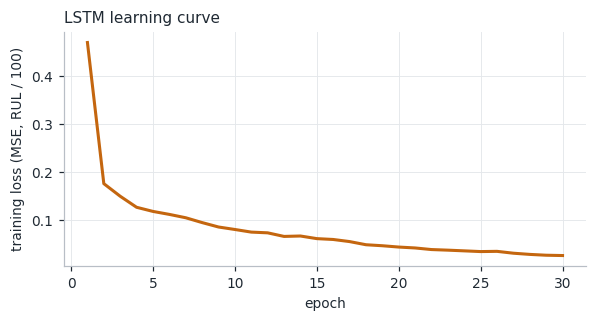

In [8]:
scaler = StandardScaler().fit(dev_df[SENSORS].to_numpy(float))


def make_sequences(df):
    # One window of the last SEQ_LEN cycles per row, in the same row order as df
    parts = []
    for _, g in df.groupby("engine_id", sort=True):
        x = scaler.transform(g.sort_values("cycle")[SENSORS].to_numpy(float))
        padded = np.vstack([np.repeat(x[:1], SEQ_LEN - 1, axis=0), x])
        windows = np.lib.stride_tricks.sliding_window_view(padded, (SEQ_LEN, x.shape[1]))[:, 0]
        parts.append(windows.astype(np.float32))
    seqs = np.concatenate(parts)
    assert len(seqs) == len(df), "sequence count must match row count"
    return seqs


class LSTMRegressor(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.lstm = nn.LSTM(n_features, LSTM_HIDDEN, num_layers=LSTM_LAYERS, batch_first=True, dropout=LSTM_DROPOUT)
        self.head = nn.Sequential(nn.Linear(LSTM_HIDDEN, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


seq_dev = make_sequences(dev_df)
print("Training windows:", seq_dev.shape, "= (rows, cycles per window, sensors)")

# window check: row 40 of the first engine should be the 30 scaled readings from cycles 11 to 40
first = dev_df[dev_df["engine_id"] == dev_ids[0]].sort_values("cycle")
expect = scaler.transform(first[SENSORS].to_numpy(float))[10:40]
assert np.allclose(seq_dev[39], expect, atol=1e-5), "window does not match the expected cycles"
print("Window check passed.")

torch.manual_seed(SEED)
lstm = LSTMRegressor(len(SENSORS)).to(DEVICE)
optimizer = torch.optim.Adam(lstm.parameters(), lr=LSTM_LR)
loss_fn = nn.MSELoss()
Xt = torch.from_numpy(seq_dev)
yt = torch.from_numpy((y_dev.to_numpy() / RUL_SCALE).astype(np.float32))
shuffler = torch.Generator().manual_seed(SEED)

loss_history = []
t0 = time.time()
for epoch in range(1, LSTM_EPOCHS + 1):
    lstm.train()
    order = torch.randperm(len(Xt), generator=shuffler)
    total = 0.0
    for i in range(0, len(order), LSTM_BATCH):
        idx = order[i:i + LSTM_BATCH]
        optimizer.zero_grad()
        loss = loss_fn(lstm(Xt[idx]), yt[idx])
        loss.backward()
        nn.utils.clip_grad_norm_(lstm.parameters(), 1.0)
        optimizer.step()
        total += loss.item() * len(idx)
    loss_history.append(total / len(order))
    if epoch == 1 or epoch % 5 == 0:
        print(f"epoch {epoch:>2}/{LSTM_EPOCHS}  training loss {loss_history[-1]:.4f}  ({time.time() - t0:.0f} s)")


@torch.no_grad()
def lstm_predict(seqs):
    lstm.eval()
    out = [lstm(torch.from_numpy(seqs[i:i + 1024])).numpy() for i in range(0, len(seqs), 1024)]
    return clip_nonneg(np.concatenate(out) * RUL_SCALE)


fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(range(1, LSTM_EPOCHS + 1), loss_history, color=COLORS["LSTM"], lw=2)
ax.set_xlabel("epoch")
ax.set_ylabel("training loss (MSE, RUL / 100)")
ax.set_title("LSTM learning curve", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 6. Evaluation on the training engines (first look)

Every row of the training engines. This asks: **how well did each model learn the data it was shown?** It is the optimistic view, and the Random Forest in particular can score very well here because it can memorise its training rows. Do not quote these numbers as the model's accuracy. Section 7 gives the honest comparison.

In [9]:
train_pred = {
    "Mean baseline": clip_nonneg(baseline.predict(X_dev)),
    "Random Forest": clip_nonneg(rf.predict(X_dev)),
    "LSTM": lstm_predict(seq_dev),
}
train_report = pd.DataFrame([regression_report(dev_df, p, n) for n, p in train_pred.items()]).set_index("model")
print(f"Training engines: {len(dev_ids)} engines, every row (the optimistic view)")
display(train_report)

Training engines: 70 engines, every row (the optimistic view)


,rows,MAE,RMSE,R2,mean signed error,over by >20 (%),engine-avg MAE,engine-avg RMSE
model,,,,,,,,
Mean baseline,14128,55.84,68.00,0.00,0.00,42.61,53.18,62.54
Random Forest,14128,10.24,15.73,0.95,-0.02,6.44,9.72,12.92
LSTM,14128,11.05,15.32,0.95,0.83,9.24,10.85,14.54


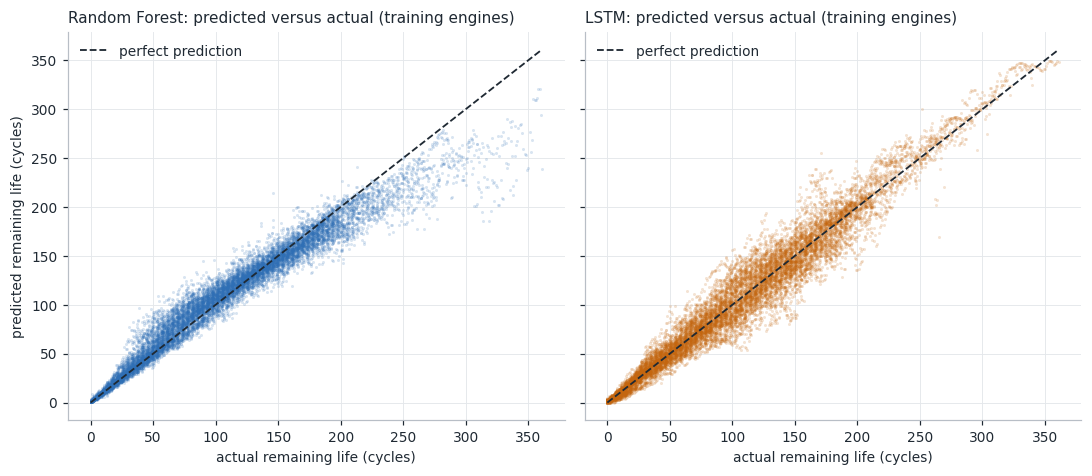

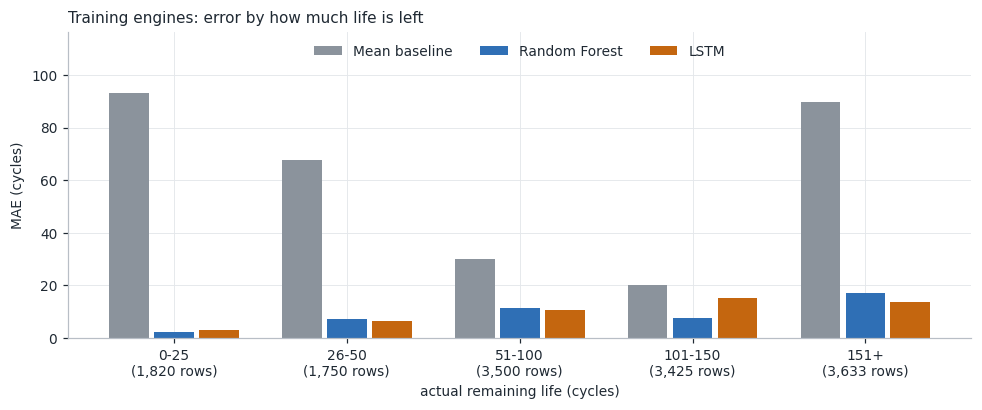

In [10]:
# ---- predicted versus actual -----------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
top = float(dev_df["rul_cycles"].max())
for ax, name in zip(axes, ["Random Forest", "LSTM"]):
    ax.scatter(dev_df["rul_cycles"], train_pred[name], s=4, alpha=0.18, color=COLORS[name], linewidths=0)
    ax.plot([0, top], [0, top], color=INK, lw=1.2, ls="--", label="perfect prediction")
    ax.set_title(f"{name}: predicted versus actual (training engines)", loc="left", fontsize=10)
    ax.set_xlabel("actual remaining life (cycles)")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("predicted remaining life (cycles)")
plt.tight_layout()
plt.show()

# ---- error by how much life is left ------------------------------------------------------
bands = pd.cut(dev_df["rul_cycles"], [-1, 25, 50, 100, 150, 1000], labels=["0-25", "26-50", "51-100", "101-150", "151+"])
by_band = pd.DataFrame({n: pd.Series(np.abs(p - dev_df["rul_cycles"].to_numpy())).groupby(bands.to_numpy()).mean()
                        for n, p in train_pred.items()}).reindex(["0-25", "26-50", "51-100", "101-150", "151+"])
counts = bands.value_counts().reindex(by_band.index)

fig, ax = plt.subplots(figsize=(9, 3.8))
width = 0.26
for i, name in enumerate(by_band.columns):
    ax.bar(np.arange(len(by_band)) + (i - 1) * width, by_band[name], width=width - 0.03, color=COLORS[name], label=name)
ax.set_xticks(range(len(by_band)))
ax.set_xticklabels([f"{b}\n({counts[b]:,} rows)" for b in by_band.index])
ax.set_xlabel("actual remaining life (cycles)")
ax.set_ylabel("MAE (cycles)")
ax.set_title("Training engines: error by how much life is left", loc="left", fontsize=10)
ax.set_ylim(0, by_band.to_numpy().max() * 1.25)
ax.legend(frameon=False, loc="upper center", ncol=3)
plt.tight_layout()
plt.show()

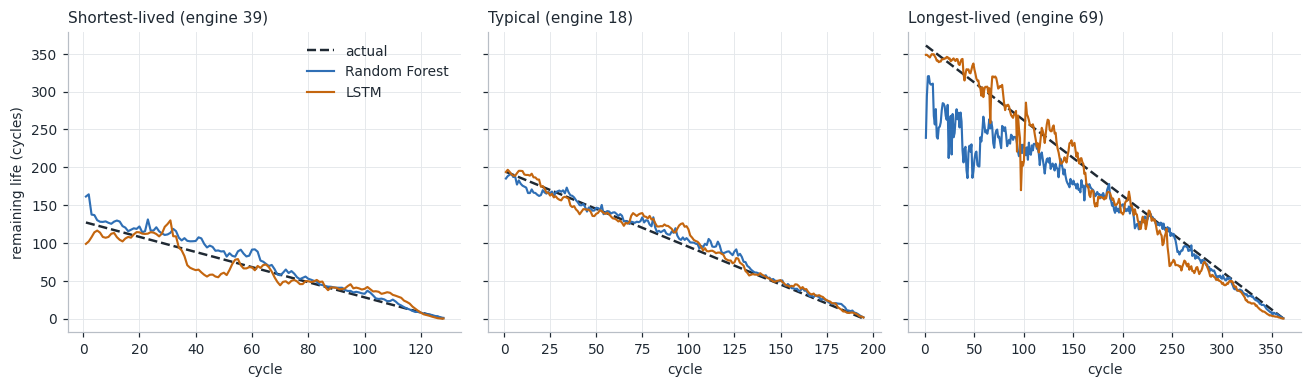

In [11]:
# ---- three example engines: prediction over the engine's life ---------------------------------
lifetimes = dev_df.groupby("engine_id")["cycle"].max()
examples = {
    "Shortest-lived": lifetimes.idxmin(),
    "Typical": (lifetimes - lifetimes.median()).abs().idxmin(),
    "Longest-lived": lifetimes.idxmax(),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (label, eid) in zip(axes, examples.items()):
    m = (dev_df["engine_id"] == eid).to_numpy()
    cyc = dev_df.loc[m, "cycle"]
    ax.plot(cyc, dev_df.loc[m, "rul_cycles"], color=INK, lw=1.6, ls="--", label="actual")
    for name in ["Random Forest", "LSTM"]:
        ax.plot(cyc, train_pred[name][m], color=COLORS[name], lw=1.4, label=name)
    ax.set_title(f"{label} (engine {eid})", loc="left", fontsize=10)
    ax.set_xlabel("cycle")
axes[0].set_ylabel("remaining life (cycles)")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

## 7. Reality check: the validation engines

These engines were set aside before any analysis and the models never saw them, so this is a fair preview of how they would do on new engines. Two views:

- **All rows.** Every row of the validation engines, scored as in section 6.
- **One endpoint per engine (FR08).** Validation engines run all the way to failure, so their last row is always RUL 0, which is much easier than the official test set. To mimic the test set, we pick **one cutoff cycle per engine at random** (fixed seed, chosen before comparing models) and score the model only at that cycle.

**Cutoff policy.** Uniform random cycle between 31 (the shortest test history) and the engine's lifetime minus 7 (the smallest remaining life among the test engines), seed 42. This is a choice made here; change `MIN_CUTOFF` or `MIN_ENDPOINT_RUL` to try another policy and the saved cutoffs will update. The two limits are summary facts about the test engines that the EDA already printed (shortest history, smallest remaining life). No per-engine test information is used anywhere. If you would rather keep the test labels completely out of the design, set `MIN_ENDPOINT_RUL = 1`.

Features and windows for any row use only that engine's earlier cycles, so scoring a cutoff row from the full history gives the same answer as truncating the history at the cutoff.

In [12]:
X_val = val_df[FEATURES]
seq_val = make_sequences(val_df)
val_pred = {
    "Mean baseline": clip_nonneg(baseline.predict(X_val)),
    "Random Forest": clip_nonneg(rf.predict(X_val)),
    "LSTM": lstm_predict(seq_val),
}

# ---- one reproducible cutoff per validation engine (FR08) ----------------------------------
rng = np.random.default_rng(SEED)
val_life = val_df.groupby("engine_id")["cycle"].max()
cut_rows = []
for eid in val_ids:
    life = int(val_life[eid])
    lo, hi = MIN_CUTOFF, life - MIN_ENDPOINT_RUL
    assert lo <= hi, f"engine {eid} is too short for the cutoff policy"
    cutoff = int(rng.integers(lo, hi + 1))
    cut_rows.append({"engine_id": eid, "lifetime": life, "cutoff_cycle": cutoff, "actual_rul": life - cutoff})
cutoffs = pd.DataFrame(cut_rows)

cut_map = cutoffs.set_index("engine_id")["cutoff_cycle"]
at_cutoff = (val_df["engine_id"].map(cut_map) == val_df["cycle"]).to_numpy()
assert at_cutoff.sum() == len(val_ids), "expected exactly one endpoint row per validation engine"
end_df = val_df[at_cutoff].reset_index(drop=True)

val_all_report = pd.DataFrame([regression_report(val_df, p, n) for n, p in val_pred.items()]).set_index("model")
val_end_report = pd.DataFrame(
    [regression_report(end_df, p[at_cutoff], n) for n, p in val_pred.items()]
).set_index("model").drop(columns=["engine-avg MAE", "engine-avg RMSE"])

print(f"Validation engines: all rows ({len(val_ids)} engines)")
display(val_all_report)
print(f"Validation engines: one endpoint per engine ({len(val_ids)} rows, FR08/FR09)")
display(val_end_report)

Validation engines: all rows (30 engines)


,rows,MAE,RMSE,R2,mean signed error,over by >20 (%),engine-avg MAE,engine-avg RMSE
model,,,,,,,,
Mean baseline,6503,58.81,70.86,-0.01,-6.82,39.67,56.36,66.11
Random Forest,6503,31.53,43.44,0.62,-11.25,19.05,30.29,39.01
LSTM,6503,29.14,42.69,0.63,-11.10,15.29,27.79,37.73


Validation engines: one endpoint per engine (30 rows, FR08/FR09)


,rows,MAE,RMSE,R2,mean signed error,over by >20 (%)
model,,,,,,
Mean baseline,30,45.14,51.49,-0.20,20.83,56.67
Random Forest,30,26.28,34.66,0.46,2.08,20.00
LSTM,30,24.28,32.69,0.52,1.94,20.00


MAE in cycles (lower is better)


,"Train: 70 engines, all rows","Validation: 30 engines, all rows",Validation: 1 endpoint per engine
model,,,
Mean baseline,55.84,58.81,45.14
Random Forest,10.24,31.53,26.28
LSTM,11.05,29.14,24.28


R2 (higher is better; 1 is perfect, 0 is no better than the average, below 0 is worse)


,"Train: 70 engines, all rows","Validation: 30 engines, all rows",Validation: 1 endpoint per engine
model,,,
Mean baseline,0.00,-0.01,-0.20
Random Forest,0.95,0.62,0.46
LSTM,0.95,0.63,0.52


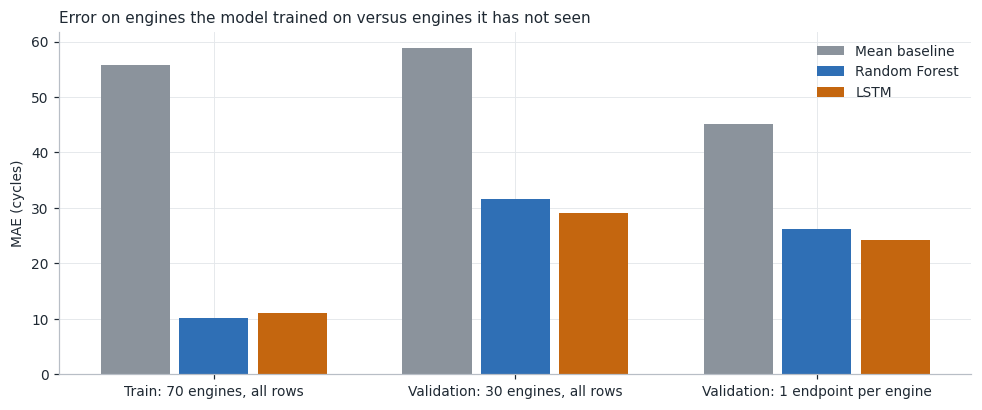

In [13]:
# ---- the headline comparison: how much worse does each model get on engines it has not seen? ----
compare = pd.DataFrame({
    TRAIN_LABEL: train_report["MAE"],
    VAL_LABEL: val_all_report["MAE"],
    END_LABEL: val_end_report["MAE"],
})
print("MAE in cycles (lower is better)")
display(compare)

r2_compare = pd.DataFrame({
    TRAIN_LABEL: train_report["R2"],
    VAL_LABEL: val_all_report["R2"],
    END_LABEL: val_end_report["R2"],
})
print("R2 (higher is better; 1 is perfect, 0 is no better than the average, below 0 is worse)")
display(r2_compare)

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(compare.columns))
for i, name in enumerate(compare.index):
    ax.bar(x + (i - 1) * width, compare.loc[name], width=width - 0.03, color=COLORS[name], label=name)
ax.set_xticks(x)
ax.set_xticklabels(compare.columns)
ax.set_ylabel("MAE (cycles)")
ax.set_title("Error on engines the model trained on versus engines it has not seen", loc="left", fontsize=10)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

,engine_id,lifetime,cutoff_cycle,actual_rul,Random Forest predicted,Random Forest error,LSTM predicted,LSTM error
0,7,259,50,209,138.75,-70.25,135.65,-73.35
1,8,150,118,32,38.84,6.84,50.64,18.64
2,12,170,118,52,55.58,3.58,69.80,17.80
3,16,209,106,103,59.47,-43.53,67.34,-35.66
4,17,276,134,142,116.55,-25.45,108.77,-33.23
5,33,200,170,30,61.82,31.82,34.51,4.51
6,35,181,43,138,154.58,16.58,171.83,33.83
7,40,188,136,52,37.39,-14.61,49.13,-2.87
8,41,216,67,149,118.01,-30.99,104.16,-44.84
9,43,207,47,160,139.60,-20.40,130.65,-29.35


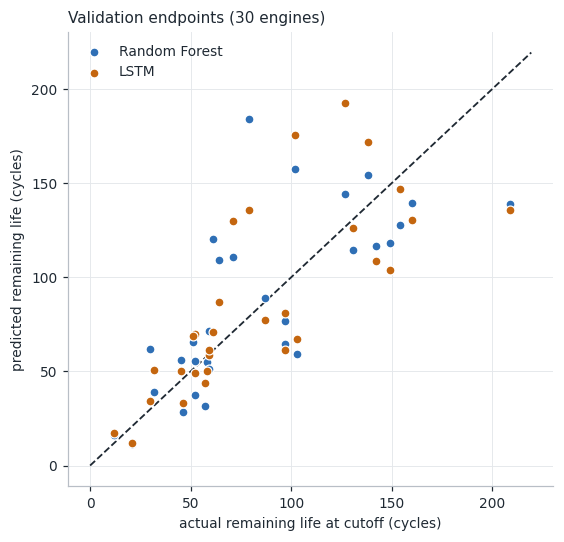

Acceptance gate (design target): MAE at least 5% below the baseline and RMSE no worse than the baseline
  Random Forest  MAE +41.8% versus baseline -> PASS
  LSTM           MAE +46.2% versus baseline -> PASS
With only 30 endpoints this is a rough check. The all-rows table above is the steadier signal.


In [14]:
# ---- per-engine endpoint results (FR09) -----------------------------------------------------------
endpoint_table = cutoffs.copy()
for name in ["Random Forest", "LSTM"]:
    endpoint_table[f"{name} predicted"] = val_pred[name][at_cutoff]
    endpoint_table[f"{name} error"] = val_pred[name][at_cutoff] - endpoint_table["actual_rul"].to_numpy()
display(endpoint_table)

fig, ax = plt.subplots(figsize=(5.2, 5))
top = float(endpoint_table["actual_rul"].max()) * 1.05
ax.plot([0, top], [0, top], color=INK, lw=1.2, ls="--")
for name in ["Random Forest", "LSTM"]:
    ax.scatter(endpoint_table["actual_rul"], endpoint_table[f"{name} predicted"], s=34, color=COLORS[name],
               edgecolor="white", linewidth=0.8, label=name, zorder=3)
ax.set_xlabel("actual remaining life at cutoff (cycles)")
ax.set_ylabel("predicted remaining life (cycles)")
ax.set_title(f"Validation endpoints ({len(val_ids)} engines)", loc="left", fontsize=10)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

# ---- design-target gate from the requirements (informational) -----------------------------------------
base = val_end_report.loc["Mean baseline"]
print("Acceptance gate (design target): MAE at least 5% below the baseline and RMSE no worse than the baseline")
for name in ["Random Forest", "LSTM"]:
    gain = 100 * (base["MAE"] - val_end_report.loc[name, "MAE"]) / base["MAE"]
    ok = gain >= 5 and val_end_report.loc[name, "RMSE"] <= base["RMSE"]
    print(f"  {name:<14} MAE {gain:+.1f}% versus baseline -> {'PASS' if ok else 'FAIL'}")
print(f"With only {len(val_ids)} endpoints this is a rough check. The all-rows table above is the steadier signal.")

## 8. Six more models

To compare more model families, these use the **same training engines, the same 60 features and the same validation engines** as the Random Forest. Every one is a first-pass setup and has **not been tuned** (FR08).

| Model | How it works, in one line | Setup used here |
| --- | --- | --- |
| Linear Regression | Fits one straight-line formula of the features | features standardised first |
| Logistic Regression | A classifier, not a regression model. See the note below | RUL cut into 10-cycle bands |
| Bayesian Ridge | Linear regression that learns for itself how strongly to shrink its coefficients, a standard Bayesian linear model | features standardised first |
| SVM | Support Vector Regression: a smooth curve fitted within a tolerance band around the data | RBF kernel, C = 100, features standardised first |
| Decision Tree | A single tree of yes/no questions on the features | depth at most 10, at least 10 rows per leaf |
| XGBoost | Many small trees built one after another, each correcting the last | 400 trees, depth 5, learning rate 0.05 |

**Logistic regression predicts categories, not numbers.** To score it on R2, RMSE and MAE like the others, RUL is cut into bands of 10 cycles (0 to 9, 10 to 19, and so on). The model learns to predict the band, and its band probabilities are turned into one number by averaging the band centres weighted by probability. The scores are comparable with the other models, but this is a workaround that gives the model a harder job than the rest, so read its row as a point of comparison.

**"Bayesian"** here means Bayesian Ridge regression. Other Bayesian models (a Gaussian process, naive Bayes) exist if you had one of those in mind.

In [15]:
LOGIT_BIN = 10   # cycles per band for the logistic regression


def timed_fit(name, model, X, y):
    t0 = time.time()
    model.fit(X, y)
    print(f"{name:<28} trained in {time.time() - t0:5.1f} s")
    return model


extra_models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Bayesian Ridge": make_pipeline(StandardScaler(), BayesianRidge()),
    "SVM (SVR)": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=100, epsilon=1.0)),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=10, random_state=SEED),
    "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                            colsample_bytree=0.8, random_state=SEED, n_jobs=-1),
}
tabular = {name: timed_fit(name, m, X_dev, y_dev) for name, m in extra_models.items()}

# ---- logistic regression on 10-cycle bands, turned back into a number ---------------------------------
bands_dev = (y_dev.to_numpy() // LOGIT_BIN).astype(int)
logit = timed_fit("Logistic Regression (bands)",
                  make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X_dev, bands_dev)
band_centres = logit[-1].classes_ * LOGIT_BIN + (LOGIT_BIN - 1) / 2.0
print(f"Logistic regression learned {len(band_centres)} bands of {LOGIT_BIN} cycles")


def predict_extra(X):
    out = {name: clip_nonneg(m.predict(X)) for name, m in tabular.items()}
    out["Logistic Regression (bands)"] = clip_nonneg(logit.predict_proba(X) @ band_centres)
    return out


more_train_pred = predict_extra(X_dev)
more_val_pred = predict_extra(X_val)

# all nine models together, in a fixed order
MODEL_ORDER = ["Mean baseline", "Linear Regression", "Logistic Regression (bands)", "Bayesian Ridge",
               "SVM (SVR)", "Decision Tree", "Random Forest", "XGBoost", "LSTM"]
all_train_pred = {**train_pred, **more_train_pred}
all_val_pred = {**val_pred, **more_val_pred}
for pred_set, n_rows in ((all_train_pred, len(dev_df)), (all_val_pred, len(val_df))):
    assert set(pred_set) == set(MODEL_ORDER), "a model is missing predictions"
    for name, p in pred_set.items():
        assert len(p) == n_rows and np.isfinite(p).all(), f"bad predictions from {name}"
print(f"\nAll {len(MODEL_ORDER)} models have predictions for the training and validation engines.")

Linear Regression            trained in   0.0 s
Bayesian Ridge               trained in   0.0 s
SVM (SVR)                    trained in  17.9 s
Decision Tree                trained in   0.5 s
XGBoost                      trained in   0.7 s


/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointwise.T @ X + l2_reg_strength * weights
/Users/joseph/Desktop/RUL_prediction/.

Logistic Regression (bands)  trained in   1.2 s
Logistic regression learned 37 bands of 10 cycles


/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/joseph/Desktop/RUL_predict


All 9 models have predictions for the training and validation engines.


/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/var/folders/gn/rxwhz96n7f7dqnmjm8p0nwgr0000gn/T/ipykernel_72231/304798968.py:31: RuntimeWarning: divide by zero encountered in matmul
  out["Logistic Regression (bands)"] = clip_nonneg(logit.predict_proba(X) @ band_centres)
/var/folders/gn/rxwhz96n7f7dqnmjm8p0nwgr0000gn/T/ipykernel_72231/304798968.py:31: RuntimeWarning: overflow encountered in matmul
  out["Logistic Regression (bands)"] = clip_nonneg(logit.predict_proba(X) @ band_centres)
/var/folders/gn/rxwhz96n7f7dqnmjm8p0nwgr0000gn/T/ipykernel_

## 9. Save the results

First this builds `final_table`, the R-Square, RMSE and MAE of all nine models on three views, which the last two cells display. Then it writes small tables under `artifacts/model/` (git-ignored) so later steps, such as MLflow logging, can reuse exactly these cutoffs and numbers (FR08, FR11).

In [16]:
# ---- R2, RMSE and MAE for all nine models on three views --------------------------------------------------
views = {
    TRAIN_LABEL: (dev_df, all_train_pred, None),
    VAL_LABEL: (val_df, all_val_pred, None),
    END_LABEL: (end_df, all_val_pred, at_cutoff),
}
records = {}
for model_name in MODEL_ORDER:
    row = {}
    for view_name, (rows, preds, mask) in views.items():
        p = preds[model_name] if mask is None else preds[model_name][mask]
        rep = regression_report(rows, p, model_name)
        for metric in ("R2", "RMSE", "MAE"):
            row[(view_name, metric)] = rep[metric]
    records[model_name] = row

final_table = pd.DataFrame.from_dict(records, orient="index")
final_table.columns = pd.MultiIndex.from_tuples(final_table.columns)
final_table.index.name = "model"

if SAVE_OUTPUTS:
    out_dir = ROOT / "artifacts" / "model"
    out_dir.mkdir(parents=True, exist_ok=True)
    summary = pd.concat(
        {"train_all_rows": train_report, "validation_all_rows": val_all_report, "validation_endpoints": val_end_report},
        names=["evaluation set"],
    ).reset_index()
    summary.to_csv(out_dir / "metrics_summary.csv", index=False)
    final_table.to_csv(out_dir / "model_comparison.csv")
    cutoffs.to_csv(out_dir / "validation_cutoffs.csv", index=False)
    endpoint_table.to_csv(out_dir / "validation_endpoint_predictions.csv", index=False)
    print("Saved to", out_dir)
    print(" ", "metrics_summary.csv, model_comparison.csv, validation_cutoffs.csv, validation_endpoint_predictions.csv")

Saved to /Users/joseph/Desktop/RUL_prediction/TurbofanHPC_RUL_prediction/artifacts/model
  metrics_summary.csv, model_comparison.csv, validation_cutoffs.csv, validation_endpoint_predictions.csv


### How to read the results, and what comes next

- **The last two cells.** They show R-Square, RMSE and MAE for all nine models, first on the training engines and then on the validation engines (all rows). Compare models on the validation table. The one-endpoint-per-engine view is also saved in `model_comparison.csv`, and treat it as rough because it has only one point per validation engine.
- **Logistic regression** is scored through a workaround (bands turned into a number), so it is not a like-for-like regression model. **Bayesian** means Bayesian Ridge. None of the models is tuned yet.
- **Training versus validation.** A model that scores far better on training engines than on validation engines has memorised rather than learned. That gap, not the training score, is what to watch.
- **Mean baseline.** Any real model must beat it on the validation tables. If it does not, the model has not found a useful signal yet.
- **R2.** Read it next to MAE, not instead of it. The mean baseline sits near 0 by construction, and it can dip below 0 on validation engines because their average life differs slightly from the training average. On the one-endpoint-per-engine view, R2 is very noisy.
- **Overestimation.** Positive mean signed error and a high "over by more than 20" share mean the model is optimistic, the riskier direction for maintenance decisions.
- **Not yet done.** No tuning (FR08), no MLflow logging (FR11), and the official test set is still unopened. Tune on validation engines, freeze the choice, then score the 100 official test endpoints once.
- **Optional diagnostics.** A cycle-only model shows how much the sensors add beyond engine age (FR07), and the 5 "review" columns from the EDA can be tested as extra inputs.

## 10. Final results: training set

R-Square (higher is better), RMSE and MAE in cycles (lower is better), for all nine models, using every row of the training engines. These models learned from these engines, so this is the optimistic view.

In [17]:
METRIC_NAMES = {"R2": "R-Square"}
train_table = final_table[TRAIN_LABEL].rename(columns=METRIC_NAMES)
print(f"TRAINING SET: {len(dev_ids)} engines, {len(dev_df):,} rows. The mean baseline is the reference to beat.\n")
display(train_table)

TRAINING SET: 70 engines, 14,128 rows. The mean baseline is the reference to beat.



,R-Square,RMSE,MAE
model,,,
Mean baseline,0.00,68.00,55.84
Linear Regression,0.61,42.23,31.12
Logistic Regression (bands),0.67,38.77,27.68
Bayesian Ridge,0.61,42.28,31.16
SVM (SVR),0.79,30.90,15.98
Decision Tree,0.78,31.94,21.12
Random Forest,0.95,15.73,10.24
XGBoost,0.91,20.89,15.36
LSTM,0.95,15.32,11.05


## 11. Final results: validation set

The same three measures on the validation engines, which no model trained on. This is the table to compare models on.

In [18]:
val_table = final_table[VAL_LABEL].rename(columns=METRIC_NAMES)
print(f"VALIDATION SET: {len(val_ids)} engines, {len(val_df):,} rows. The mean baseline is the reference to beat.\n")
display(val_table)

ranked = val_table.drop(index="Mean baseline")
print(f"\nBest R-Square: {ranked['R-Square'].idxmax()} | lowest RMSE: {ranked['RMSE'].idxmin()} | "
      f"lowest MAE: {ranked['MAE'].idxmin()}. Untuned first-pass models, so treat the ranking as a rough guide.")

VALIDATION SET: 30 engines, 6,503 rows. The mean baseline is the reference to beat.



,R-Square,RMSE,MAE
model,,,
Mean baseline,-0.01,70.86,58.81
Linear Regression,0.62,43.28,32.11
Logistic Regression (bands),0.61,43.81,31.51
Bayesian Ridge,0.62,43.32,32.13
SVM (SVR),0.57,46.37,33.60
Decision Tree,0.51,49.54,35.90
Random Forest,0.62,43.44,31.53
XGBoost,0.62,43.59,31.66
LSTM,0.63,42.69,29.14



Best R-Square: LSTM | lowest RMSE: LSTM | lowest MAE: LSTM. Untuned first-pass models, so treat the ranking as a rough guide.
